# 02 · Part 2: HNSW, IVF-Flat and IVF-PQ

On both datasets, each index is built with a few settings, and each build's search parameter (efSearch or nprobe) is swept from low recall upwards. A sweep stops once the tune-half recall reaches `recall_stop`, or at the end of the grid.

Every setting is timed one query at a time on one pinned thread (median of `repeats` passes), and scored with our recall@10 on both query halves. Configurations are chosen on the tune half; the numbers reported are from the report half. The exact baseline comes from Part 1, timed with the same protocol on the same base set. Measurement choices are listed in `design_note.md`.

In [1]:
%run ./00_core.ipynb

.

.

.

.

.

...

                                                                                         [100%]

.

.

                                                                                           [100%]

mode=full  results -> results  timing CPU 2  build threads 12


## Grids
The grids for this mode come from `CONFIG`. IVF-PQ uses 8-bit codes (FAISS's default), so m sub-vectors take m bytes per vector, and m must divide the dimension. nprobe values above `ivf_max_probe_fraction` × nlist are skipped: in full mode an IVF index never scans more than a quarter of its lists.

In [2]:
def part2_configs(name, config=CONFIG):
    """(index kind, build settings, search values) for every Part 2 build on dataset `name`."""
    probes = lambda nlist: [p for p in config["nprobe"] if p <= nlist * config["ivf_max_probe_fraction"]]
    return ([("hnsw", dict(M=M, efC=config["hnsw_efC"]), config["ef_search"]) for M in config["hnsw_M"]]
            + [("ivf_flat", dict(nlist=nlist), probes(nlist)) for nlist in config["ivf_nlist"]]
            + [("ivf_pq", dict(nlist=config["ivfpq_nlist"], m=m), probes(config["ivfpq_nlist"]))
               for m in config["ivfpq_m"][name]])


pd.DataFrame([dict(dataset=name, index=kind, build=json.dumps(params), search=f"{SEARCH_PARAM[kind]} in {values}")
              for name in DATASETS for kind, params, values in part2_configs(name)])

,dataset,index,build,search
0,sift,hnsw,"{""M"": 8, ""efC"": 200}","efSearch in [10, 16, 24, 32, 48, 64, 96, 128, ..."
1,sift,hnsw,"{""M"": 16, ""efC"": 200}","efSearch in [10, 16, 24, 32, 48, 64, 96, 128, ..."
2,sift,hnsw,"{""M"": 32, ""efC"": 200}","efSearch in [10, 16, 24, 32, 48, 64, 96, 128, ..."
3,sift,ivf_flat,"{""nlist"": 1024}","nprobe in [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 4..."
4,sift,ivf_flat,"{""nlist"": 4096}","nprobe in [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 4..."
5,sift,ivf_pq,"{""nlist"": 4096, ""m"": 16}","nprobe in [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 4..."
6,sift,ivf_pq,"{""nlist"": 4096, ""m"": 32}","nprobe in [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 4..."
7,sift,ivf_pq,"{""nlist"": 4096, ""m"": 64}","nprobe in [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 4..."
8,glove,hnsw,"{""M"": 8, ""efC"": 200}","efSearch in [10, 16, 24, 32, 48, 64, 96, 128, ..."
9,glove,hnsw,"{""M"": 16, ""efC"": 200}","efSearch in [10, 16, 24, 32, 48, 64, 96, 128, ..."


In [3]:
%%ipytest -qq

@pytest.mark.parametrize("name", ["sift", "glove"])
def test_full_grid_tries_several_build_settings_per_index(name):
    kinds = [kind for kind, _, _ in part2_configs(name, FULL)]
    assert all(kinds.count(kind) >= 2 for kind in ("hnsw", "ivf_flat", "ivf_pq"))


@pytest.mark.parametrize("config", [FULL, QUICK], ids=["full", "quick"])
def test_every_index_runs_and_nprobe_stays_within_its_share_of_the_lists(config):
    for name in DATASETS:
        runs = part2_configs(name, config)
        assert {kind for kind, _, _ in runs} == {"hnsw", "ivf_flat", "ivf_pq"}
        assert all(max(values) <= params["nlist"] * config["ivf_max_probe_fraction"]
                   for kind, params, values in runs if kind != "hnsw")


def test_full_grid_reaches_2048_and_a_quarter_of_the_lists():
    runs = {(kind, params.get("nlist")): values for kind, params, values in part2_configs("glove", FULL)}
    assert runs[("hnsw", None)][-1] == 2048
    assert runs[("ivf_flat", 4096)][-1] == 1024 and runs[("ivf_flat", 1024)][-1] == 256

.

.

.

.

.

                                                                                        [100%]

## Run
Each dataset's rows are written to `results.csv` as soon as its runs finish, so a failure on the second dataset keeps the first.

In [4]:
for name in DATASETS:
    started = time.perf_counter()
    data = load_dataset(name, CONFIG["n_base"])
    gt = ground_truth(name, data.base, data.queries)
    rows = []
    for kind, params, values in part2_configs(name):
        rows += benchmark_index(2, name, data, gt, kind, params, values)
    write_rows(rows, part=2, section=name)
    print(f"{name}: {len(rows)} rows in {(time.perf_counter() - started) / 60:.1f} min")
    del data, gt

sift  hnsw {'M': 8, 'efC': 200}: built in 36.0 s, best tune recall 0.996


sift  hnsw {'M': 16, 'efC': 200}: built in 51.6 s, best tune recall 0.996


sift  hnsw {'M': 32, 'efC': 200}: built in 62.8 s, best tune recall 0.995


sift  ivf_flat {'nlist': 1024}: built in 4.0 s, best tune recall 0.996


sift  ivf_flat {'nlist': 4096}: built in 49.2 s, best tune recall 0.998


...

glove  hnsw {'M': 32, 'efC': 200}: built in 107.2 s, best tune recall 0.994


glove  ivf_flat {'nlist': 1024}: built in 3.3 s, best tune recall 0.980


glove  ivf_flat {'nlist': 4096}: built in 41.7 s, best tune recall 0.987


glove  ivf_pq {'nlist': 4096, 'm': 20}: built in 51.1 s, best tune recall 0.540


glove  ivf_pq {'nlist': 4096, 'm': 50}: built in 55.7 s, best tune recall 0.869
glove: 248 rows in 61.7 min


## Recall against speed
Each line is an index's best trade-off curve: the tune-half Pareto front over all its build settings and search values, drawn at its report-half recall and QPS. Faint dots are every configuration measured (report half). The grey line and diamond are exact search from Part 1. The vertical lines mark recall 0.90 and 0.95.

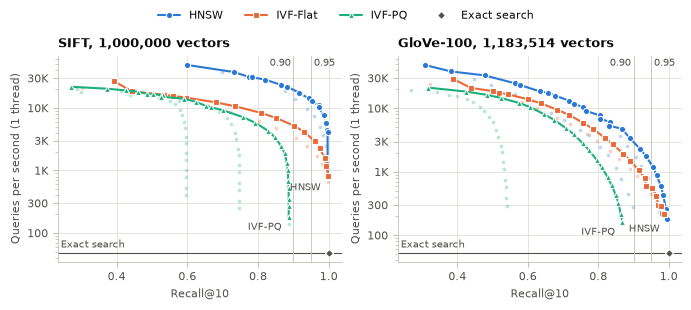

In [5]:
results = read_results()
figure, tables = part2_assets(results)
plt.show()

## Tables
- **QPS at recall 0.90 and 0.95:** the fastest configuration whose tune-half recall reaches the target, with its report-half recall and QPS.
- **Cost at recall 0.95:** that configuration's build time, serialised size and bytes per vector, plus the RAM IVF-PQ keeps for its precomputed search table. An index that never reaches 0.95 is shown at its highest-recall configuration and marked "no".
- **Highest recall reached:** for every build, the best tune-half recall in its sweep. This is the evidence for any index that fails to reach high recall.

In [6]:
for name, table in tables.items():
    print(name)
    display(table)

part2_qps_at_recall


,Dataset,Index,Setting for 0.90,Recall (0.90),QPS (0.90),Setting for 0.95,Recall (0.95),QPS (0.95)
0,SIFT,HNSW,"M=16, efSearch=32",0.918,"17,507","M=16, efSearch=64",0.971,"11,093"
1,SIFT,IVF-Flat,"nlist=4096, nprobe=32",0.930,"4,150","nlist=4096, nprobe=48",0.960,"2,955"
2,SIFT,IVF-PQ,not reached,,,not reached,,
3,SIFT,Exact search,full scan,1.000,48.6,full scan,1.000,48.6
4,GloVe-100,HNSW,"M=32, efSearch=192",0.918,"2,320","M=32, efSearch=384",0.955,"1,201"
5,GloVe-100,IVF-Flat,"nlist=4096, nprobe=192",0.915,"1,048","nlist=4096, nprobe=384",0.953,553
6,GloVe-100,IVF-PQ,not reached,,,not reached,,
7,GloVe-100,Exact search,full scan,1.000,53.3,full scan,1.000,53.3


part2_cost_at_095


,Dataset,Index,Setting,Reaches 0.95,Recall,QPS,Build (s),Size (MB),Bytes/vector,Search table (MB)
0,SIFT,HNSW,"M=16, efSearch=64",yes,0.971,"11,093",51.6,656.3,656,0.0
1,SIFT,IVF-Flat,"nlist=4096, nprobe=48",yes,0.960,"2,955",49.2,522.1,522,0.0
2,SIFT,IVF-PQ,"nlist=4096, m=64, nprobe=768",no,0.887,181,68.5,74.3,74,268.4
3,SIFT,Exact search,full scan,yes,1.000,48.6,0.1,512.0,512,0.0
4,GloVe-100,HNSW,"M=32, efSearch=384",yes,0.955,"1,201",107.2,795.5,672,0.0
5,GloVe-100,IVF-Flat,"nlist=4096, nprobe=384",yes,0.953,553,41.7,484.5,409,0.0
6,GloVe-100,IVF-PQ,"nlist=4096, m=50, nprobe=1024",no,0.868,163,55.7,70.4,59,209.7
7,GloVe-100,Exact search,full scan,yes,1.000,53.3,0.1,473.4,400,0.0


part2_best_recall


,Dataset,Index,Build,Best search setting,Largest swept,Tune recall,Report recall
0,SIFT,HNSW,M=8,efSearch=1024,1024,0.996,0.997
1,SIFT,HNSW,M=16,efSearch=192,192,0.996,0.996
2,SIFT,HNSW,M=32,efSearch=128,128,0.995,0.996
3,SIFT,IVF-Flat,nlist=1024,nprobe=64,64,0.996,0.997
4,SIFT,IVF-Flat,nlist=4096,nprobe=192,192,0.998,0.998
5,SIFT,IVF-PQ,"nlist=4096, m=16",nprobe=512,1024,0.586,0.596
6,SIFT,IVF-PQ,"nlist=4096, m=32",nprobe=768,1024,0.736,0.746
7,SIFT,IVF-PQ,"nlist=4096, m=64",nprobe=768,1024,0.884,0.887
8,GloVe-100,HNSW,M=8,efSearch=2048,2048,0.898,0.897
9,GloVe-100,HNSW,M=16,efSearch=2048,2048,0.973,0.972


In [7]:
%%ipytest -qq

part2 = results[results["part"] == 2]


def test_every_setting_is_measured_on_both_halves():
    splits = part2.groupby(["dataset", "index", "build_params", "param_value"])["split"].agg(frozenset)
    assert (splits == frozenset({"tune", "report"})).all()


def test_hnsw_and_ivf_flat_reach_the_top_of_the_recall_range():
    best = part2[part2["split"] == "tune"].groupby(["dataset", "index"])["recall_at_10"].max().unstack()
    assert (best[["hnsw", "ivf_flat"]] >= 0.95).all().all()


def test_tables_cover_every_index_and_exact_search_on_both_datasets():
    for table in (qps_at_recall_table(results), cost_at_recall_table(results)):
        assert len(table) == len(DATASETS) * 4
    assert (FIGURES_DIR / "part2_recall_qps.pdf").exists() and (TABLES_DIR / "part2_qps_at_recall.tex").exists()

.

.

.

                                                                                          [100%]